# Week 3: From Experiments to Observational Studies

This notebook follows the Week 3 page, in the same order:
<https://yoonismo.github.io/causal-computing/week3.html>

Read the explanations on the page and run the cells here **in order** from top to bottom. Some cells ask you to write code yourself: they are marked `# TODO`, and each is followed by a **check** cell. Write your answers to the questions in the empty text cells.

## 0. Before you start

- Check **Select Kernel** at the top right: it should say **ECON 481 (Python 3.12)**.
- If a cell fails with `ModuleNotFoundError`, a package is missing from your environment. See `README.md`.
- The data sets are downloaded from the internet when you load them, so you need a connection.
- A check cell prints `not done yet` until you fill in the `# TODO` cell above it. Every cell must still run from top to bottom when you push: GitHub runs this notebook after every push.

First, we fix the random seed for reproducibility. 

In [ ]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(481)

## Why do we need observational studies?

Randomized experiments give clean answers, but for many questions we cannot run one:

- **It would be unethical.** We cannot "randomly" assign people to smoke. We cannot make people "randomly" drop out of school.
- **It would be too costly or too slow.** An experiment on how college affects lifetime earnings would take decades.
- **The policy already happened.** A state raised its minimum wage last year; we can only look at what followed.
- **Large observational data already exist.** Surveys and administrative records cover millions of people.


Observational studies allow us to answer causal questions when randomized experiments are not available. However, they bring more challenges when we attempt to measure causal quantities of interest. We will study: 

- what happens if we estimate a causal effect under a non-random treatment assignment as in a randomized experiment,
- under which assumptions we can estimate causal effects as we did in randomized experiments, 
- what challenges these assumptions incur, 
- how to address the challenges, i.e., how to estimate to overcome the issues. 

## Lab 1 — When the choice depends only on who we are

We are going to run a simulation in which we know both potential outcomes, as in Week 2, Lab 1. Think of $Y_i(0)$ as annual earnings (in thousands of dollars) without a job-training program, and suppose the program raises everyone's earnings by exactly $\tau = 2$.

How is the simulation different from the one in Week 2? Now we let people decide whether to join. Suppose the decision depends only on one variable or covariate: $X_i = 1$ if person $i$ has a college degree and $X_i = 0$ otherwise. We set that people with a degree earn more, and they rarely join a job-training program:

$$
Y_i(1) = 8 + 2+ 6 X_i + \varepsilon_i, \qquad
Y_i(0) = 8 + 6 X_i + \varepsilon_i, \qquad
P(D_i = 1 \mid X_i) = \begin{cases} 0.1 & \text{if } X_i = 1 \\ 0.6 & \text{if } X_i = 0 \end{cases}
$$

where $\varepsilon_i$ is random noise (variables that we cannot observe) unrelated to the decision.

In [ ]:
n = 10000
tau = 2
x = rng.binomial(1, 0.5, n)                        # 1 = college degree (observed)
y0 = 8 + 6 * x + rng.normal(0, 2, n)               # Y(0): earnings without the program
y1 = y0 + tau                                      # Y(1): the same effect, 2, for everyone
d = rng.binomial(1, np.where(x == 1, 0.1, 0.6))    # the decision depends on x only
y = d * y1 + (1 - d) * y0                          # what we observe

print("Simple difference:", round(y[d == 1].mean() - y[d == 0].mean(), 3))


The simple difference is badly wrong. Why does this happen? Because we did not consider the following: by the simulation setting, the treatment group has fewer people with college degree than the people with degree in the control group. So the simple difference without the consideration yielded the sign reversal of estimate of ATE, leading to a wrong conclusion. Then how do we correct the bias so that we recover the causal parameter ATE?

## Identification assumptions in observational studies

We need two assumptions in observational studies in order to estimate causal effects. We state the first assumption.

### Unconfoundedness

**Assumption (unconfoundedness, or conditional independence).**

$$
(Y_i(1), Y_i(0)) \perp D_i \mid X_i .
$$

The direct interpretation of unconfoundedness assumption is that treatment assignment is independent of the potential outcomes given every value of $X$. In other words, among people with the same values of $X$, who is treated is as good as random. This allows us to write population causal effects in terms of quantities that we can estimate using data. 


Let me show how we can use the unconfoundedness assumption to write causal effects with observable quantities: 

$$
\begin{align*}
    \tau_{\text{ATE}} =& E[Y_i(1)- Y_i(0)]\\
                      =& E\big[E[Y_i(1)- Y_i(0)|X_i]\big] \tag{Law of iterated expectations}\\
                      =& E\big[E[Y_i(1)|X_i] - E[Y_i(0)|X_i]\big] \\
                      =& E\big[E[Y_i(1)|D_i = 1, X_i] - E[Y_i(0)|D_i = 0, X_i]\big] \tag{Unconfoundedness}\\
                      =& E\big[E[Y_i|D_i = 1, X_i] - E[Y_i|D_i = 0, X_i]\big] \tag{consistency}\\
\end{align*}
$$

Note that the outer expectation is over $X$. How do we estimate the above? 

$$
    \hat{\tau}_{\text{ATE}} = \frac{N_1}{N}\bigg[\frac{1}{n_{11}} \sum_{i: D_i =1 , X_i = 1} Y_i - \frac{1}{n_{01}} \sum_{i: D_i =0 ,X_i = 1} Y_i\bigg] + \frac{N_0}{N}\bigg[\frac{1}{n_{10}} \sum_{i: D_i =1 , X_i = 0} Y_i - \frac{1}{n_{00}} \sum_{i: D_i =0 ,X_i = 0} Y_i\bigg]
$$

where $N_x$ is the number of units that have $X = x$, and $n_{dx}$ is the number of units that are assigned to treatment $d$ and have $X=x$, $d, x \in \{0,1\}$.

In [ ]:
gap_1 = y[(x == 1) & (d == 1)].mean() - y[(x == 1) & (d == 0)].mean()
gap_0 = y[(x == 0) & (d == 1)].mean() - y[(x == 0) & (d == 0)].mean()
weight_1 = ((x == 1)).sum() / len(x)      # share of everyone in group X = 1, with college degree
weight_0 = ((x == 0)).sum() / len(x)    # share of everyone in group X = 0, without it

ate_hat = weight_1*gap_1 + weight_0*gap_0
print("Weighted within-group difference (ATE):", round(ate_hat, 3))

Now we have an estimate close to the true ATE. However, can we use this approach to estimate the ATE for "any" given data set?

Let's take a look at the size of four groups to estimate the four causal quantities above. The first subscript indicates the treatment assignment, $d \in \{0,1\}$ and the second the covariate value $x\in \{0,1\}$.

In [ ]:
len_11 = ((x == 1) & (d == 1)).sum()
len_01 = ((x == 1) & (d == 0)).sum()
len_10 = ((x == 0) & (d == 1)).sum()
len_00 = ((x == 0) & (d == 0)).sum()

print(len_11, len_10, len_01, len_00)

More simply, 

In [ ]:
pd.crosstab(x, d, rownames=["X (degree)"], colnames=["D (joined)"])

The groups have different sizes. What if we add more covariates? Is it always assured that the size of "every" group in both treatment and control group is nonzero? We cannot say that. We need a second assumption to solve this issue. 

### Common support (overlap, a.k.a. positivity)

$$
0 < P(D_i = 1 \mid X_i = x) < 1 \quad \text{for every } x .
$$

Within every group there must be both treated and untreated people; otherwise there is nobody to compare with. For the ATT it is enough that $P(D_i = 0 \mid X_i = x) > 0$ wherever there are treated people.


## Lab 2 — Real data: LaLonde's question

In Week 2 we estimated the effect of the National Supported Work (NSW) program from its experiment: about **1,794** dollars of extra 1978 earnings for the trainees. LaLonde (1986) asked: if there had been no experiment, could we recover this number by comparing the trainees with men from a national survey, the **Current Population Survey (CPS)**?

Here $D_i = 1$ for an NSW trainee and $D_i = 0$ for a CPS man, $Y_i$ is 1978 earnings (`re78`), and $X_i$ the characteristics measured before the program (age, education, race, marital status, degree, 1974 and 1975 earnings). Because the experiment gives us the answer, we can grade every method.

In [ ]:
import numpy as np
import pandas as pd
from causaldata import nsw_mixtape, cps_mixtape

nsw = nsw_mixtape.load_pandas().data
cps = cps_mixtape.load_pandas().data

treated = nsw[nsw["treat"] == 1].copy()    # 185 NSW trainees
control = nsw[nsw["treat"] == 0].copy()    # 260 NSW random controls (only for the benchmark)
comparison = cps.copy()                    # 15,992 CPS men: the non-experimental comparison group

benchmark = treated["re78"].mean() - control["re78"].mean()   # experimental estimate (Week 2)
print("Experimental benchmark:", round(benchmark, 1))

What if we compare the treatment group in the NSW data set and the people in the CPS data set? 

In [ ]:
naive = treated["re78"].mean() - comparison["re78"].mean()    # treated minus CPS
print("Naive NSW - CPS:       ", round(naive, 1))

We observe that there are severe bias in the estimate. How do we correct it? First we consider what covariates we use. 

In [ ]:
covariates = ["age", "educ", "black", "hisp", "marr", "nodegree", "re74", "re75"]

Before any adjustment, compare the treatment group in the NSW to the two control groups in the NSW and in the CPS, respectively.

In [ ]:
pd.DataFrame({
    "NSW trainees": treated[covariates].mean(),
    "NSW controls": control[covariates].mean(),
    "CPS men": comparison[covariates].mean(),
}).round(2)

The same comparison in pictures. First, the whole distribution of one covariate, age, in its own units (years): trainees against CPS men.

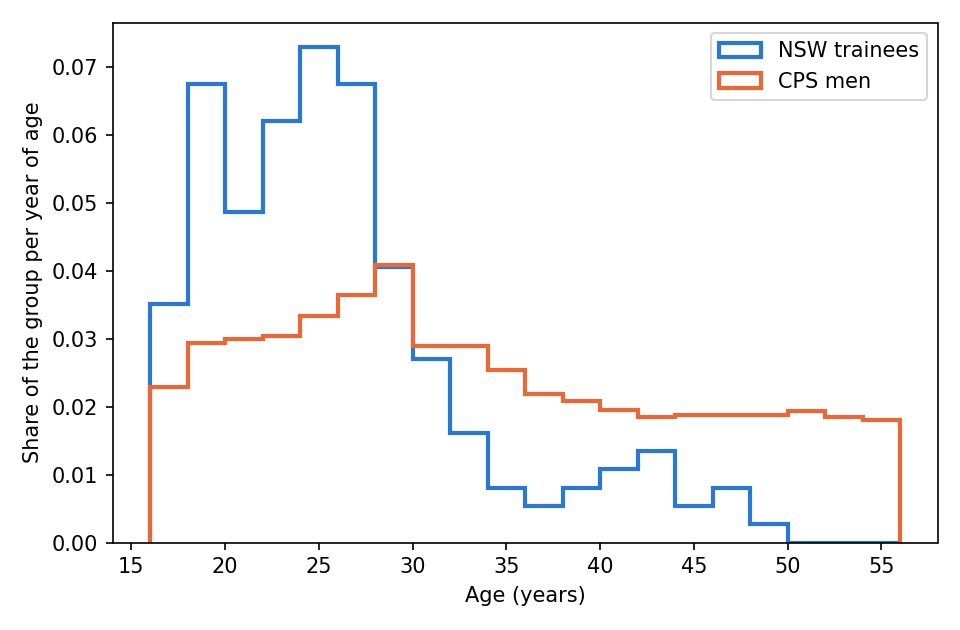

Covariates have different units (years, dollars, 0/1), so to put all of them in one picture we use the **standardized difference** from the Week 2 balance check:

$$
\text{std. diff.} = \frac{\overline{X}_1 - \overline{X}_0}{\sqrt{(s_{X,1}^2 + s_{X,0}^2) / 2}},
$$

here with the trainees as group 1 and the CPS men as group 0. A value of 1 means the two means are one standard deviation apart. The dashed lines at $\pm 0.1$ are a common rule of thumb for "small" (Austin, 2009); it is a convention, not a test.

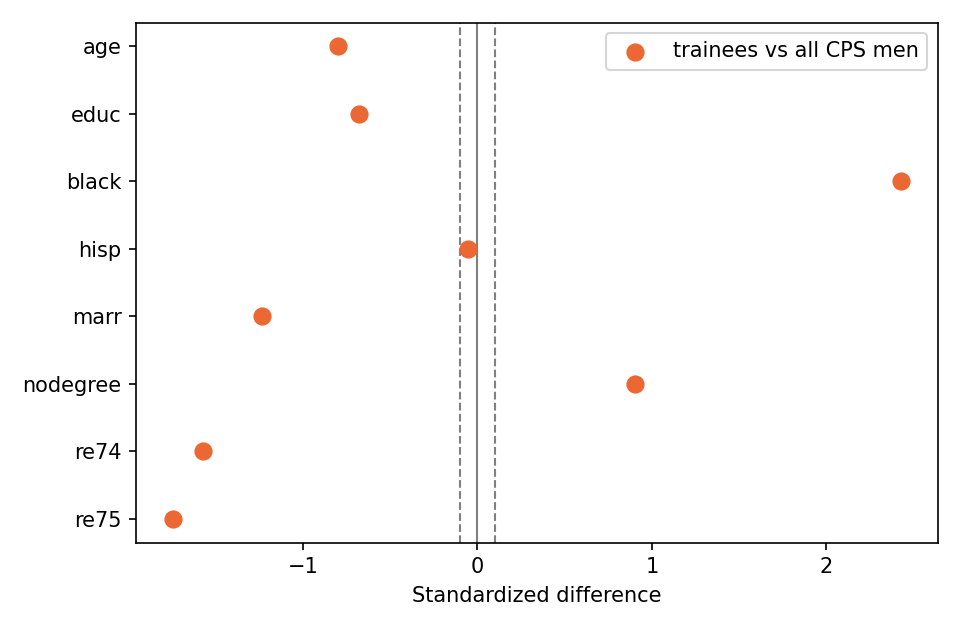

The trainees and the CPS men differ in almost every covariate: the CPS men are older, more educated, more often married, rarely black, and earned far more in 1974 and 1975. This **covariate imbalance** is why the naive comparison fails. The rest of this week corrects it in two ways: subclassification and matching. (For a longer discussion of this data exercise, see the [Mixtape, Section 5.10](https://mixtape.scunning.com/05-causal_cross_sectional_designs#national-support-work-demonstration-data-exercise).)

A first, informal attempt: keep only the CPS men who look like the trainees, using a few rules picked by hand.

In [ ]:
q95 = treated["re75"].quantile(0.95)    # 95% of the trainees earned at most this in 1975; the top 5% are outliers

rules = {
    "all CPS": comparison,
    "CPS, re75 at most the trainees' 95th pct.": comparison[comparison["re75"] <= q95],
    "CPS, no high school degree": comparison[comparison["nodegree"] == 1],   # nodegree = 1 means educ < 12
}
for label, group in rules.items():
    gap = treated["re78"].mean() - group["re78"].mean()
    print(f"{label:42s} n = {len(group):6d}   gap = {gap:9.1f}")

**Question 1.** The answer moves a lot with the rule. What should a good rule be based on, and why? The rest of this week turns this informal idea into methods: subclassification compares within cells of equal $X$, exactly as in the simulation of Lab 1, and matching compares each trainee with the most similar CPS men.

*Your answer to Question 1:*

## Lab 3 — Subclassification

Subclassification does what we did in the college-degree simulation, with more covariates. Split both groups by the values of the covariates, as in the tree below with two covariates: $X_1 \in \{0, 1\}$ and $X_2 \in \{-1, 0, 1\}$. Each leaf on the left has a partner on the right with the **same** $X$ and the other $D$. Inside each pair, who is treated is as good as random (unconfoundedness), so we compare the mean outcomes there.

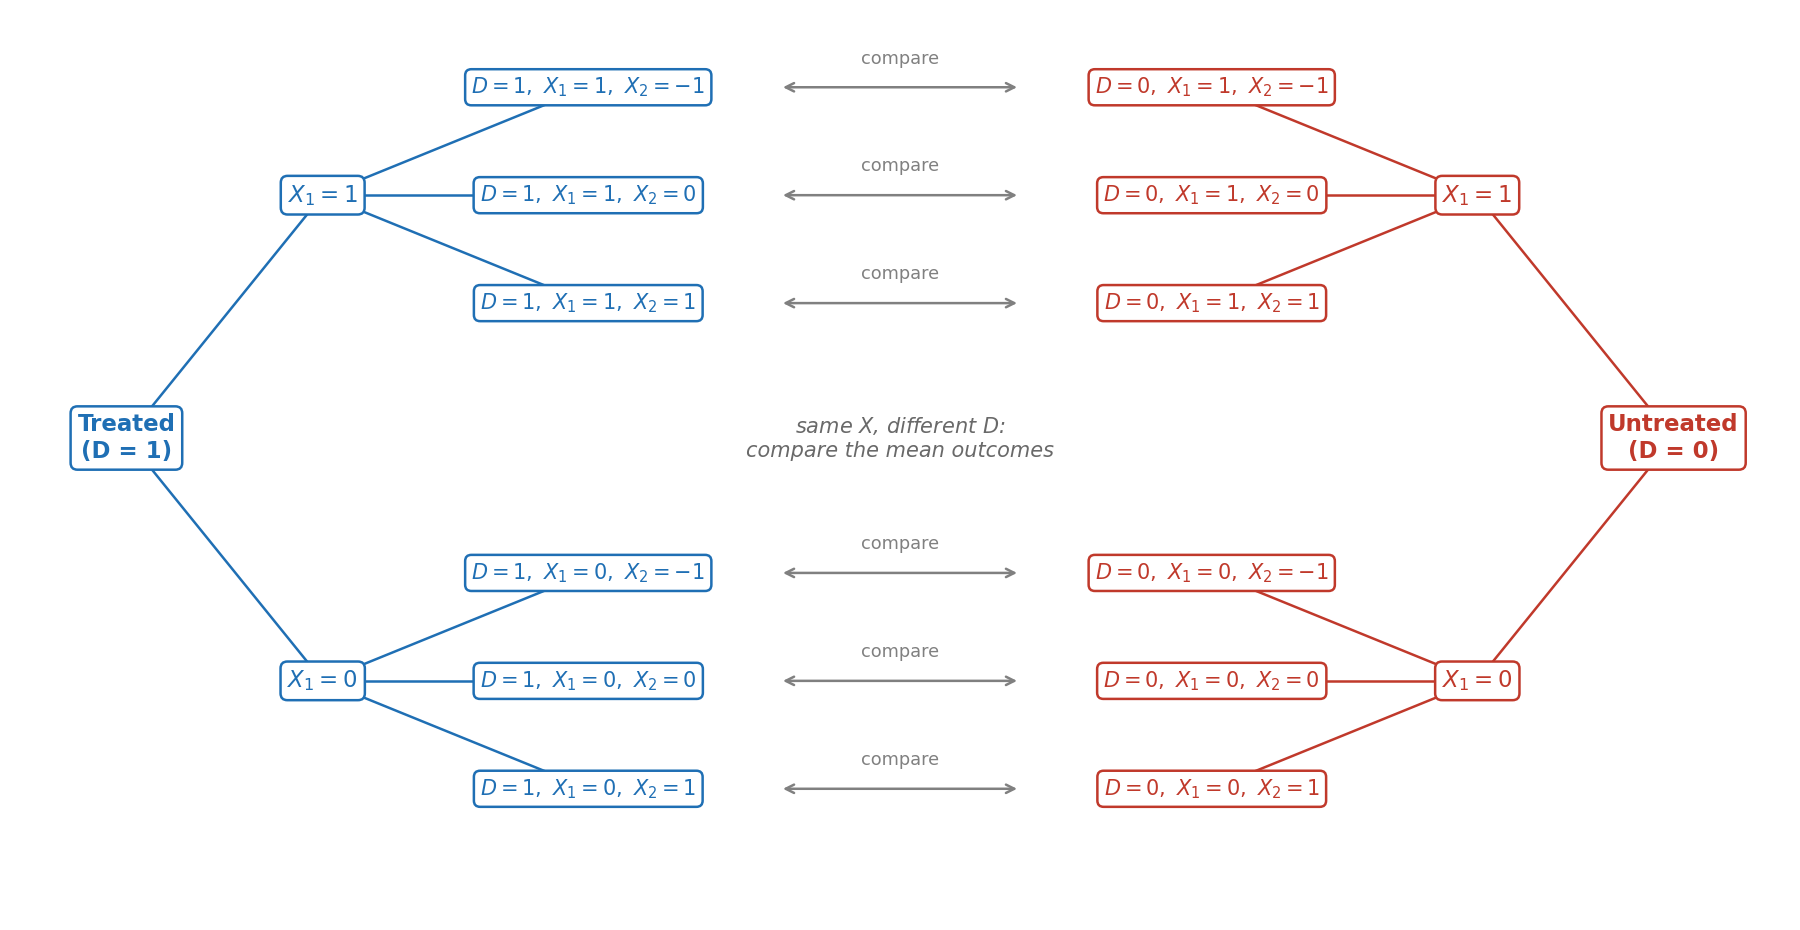

For each pair of leaves, the difference in mean outcomes is

$$
\Delta(x_1, x_2) = \overline{Y}_{[D=1,\, X_1=x_1,\, X_2=x_2]} - \overline{Y}_{[D=0,\, X_1=x_1,\, X_2=x_2]} .
$$

For the ATT, average the six differences, weighting each by its share of the **treated**:

$$
\hat\tau_{\text{ATT}} = \sum_{x_1 \in \{0,1\}} \; \sum_{x_2 \in \{-1,0,1\}} \frac{n_{[D=1,\, X_1=x_1,\, X_2=x_2]}}{n_{D=1}} \, \Delta(x_1, x_2),
$$

where $n_{[\cdot]}$ is the number of people in the leaf and $n_{D=1}$ the number of treated. If a leaf on the right is empty, there is nobody to compare with: common support fails for that leaf.

### 3.1 One covariate: no high school degree

The covariate table in Lab 2 shows that 71% of the trainees but only 30% of the CPS men have no high school degree. Start with this one binary covariate, `nodegree`: the tree has only two leaves on each side.

First by hand, one cell at a time:

In [ ]:
N1 = len(treated)
att_sub = 0.0
for k in [0, 1]:
    t_k = treated[treated["nodegree"] == k]          # trainees in cell k
    c_k = comparison[comparison["nodegree"] == k]    # CPS men in cell k
    ybar1_k = t_k["re78"].sum() / len(t_k)
    ybar0_k = c_k["re78"].sum() / len(c_k)
    weight_k = len(t_k) / N1                         # share of the trainees in cell k
    print(f"nodegree = {k}: treated {len(t_k):4d}, CPS {len(c_k):6d}, difference {ybar1_k - ybar0_k:9.1f}, weight {weight_k:.3f}")
    att_sub += weight_k * (ybar1_k - ybar0_k)

print("Subclassification ATT:", round(att_sub, 1))

The same with `pandas`: group both data sets by the cell, then combine.

In [ ]:
def subclass_att(cols):
    """Subclassification estimate of the ATT using the cells defined by the columns in cols."""
    g1 = treated.groupby(cols, observed=True)["re78"].agg(y1="mean", n1="size")     # one row per cell with trainees
    g0 = comparison.groupby(cols, observed=True)["re78"].agg(y0="mean", n0="size")  # one row per cell with CPS men
    cells = g1.join(g0, how="outer")                     # every cell that has anyone in it
    no_treated = cells["n1"].isna()                      # CPS men but no trainee
    no_control = cells["n0"].isna()                      # trainees but no CPS man: nobody to compare with
    kept = cells[~no_treated & ~no_control]
    att = (kept["n1"] * (kept["y1"] - kept["y0"])).sum() / kept["n1"].sum()
    return {"cells without treated": int(no_treated.sum()), "cells without control": int(no_control.sum()),
            "ATT": round(float(att), 1)}

subclass_att(["nodegree"])

### 3.2 Adding covariates

Now add covariates one by one: race, marital status, age and education. Age is grouped into five bands so that it can define cells.

In [ ]:
bands = [0, 20, 25, 30, 35, 100]
for df in (treated, comparison):
    df["age_band"] = pd.cut(df["age"], bands)

steps = [
    ["nodegree"],
    ["nodegree", "black"],
    ["nodegree", "black", "marr", "hisp"],
    ["nodegree", "black", "marr", "hisp", "age_band"],
    ["nodegree", "black", "marr", "hisp", "age_band", "educ"],
]
table = pd.DataFrame([subclass_att(s) for s in steps],
                     index=[" + ".join(s) for s in steps])
table

How to read the table. Each row uses the covariates in its name to build the cells.

- **cells without treated**: cells with CPS men but no trainee. They are not used for the ATT.
- **cells without control**: cells with trainees but no CPS man. There is nobody to compare with, so the trainees in these cells are left out of the estimate.
- **ATT**: the subclassification estimate from the remaining trainees. Compare it with the benchmark 1,794.

### 3.3 The curse of dimensionality

Every covariate we add splits each cell into two or more smaller cells. The number of cells grows very fast, but the number of people stays the same, so each cell holds fewer and fewer people. Soon some cells contain trainees but no CPS men. In those cells common support fails, and the trainees there must be dropped (the last row of the table). The estimate then describes only the trainees who remain, not all trainees. This problem is called the **curse of dimensionality**.

**Question 2.** In the table, which rows get closer to 1,794 and which move away? Why do some trainees disappear from the estimate in the last row? What population does the last row's ATT refer to?

*Your answer to Question 2:*

## Lab 4 — Exact matching

Take the finest cells possible: match each trainee to the CPS men with **exactly** the same value of every covariate. For trainee $i$, let $\mathcal{J}(i)$ be the set of CPS men with $X_j = X_i$ and $|\mathcal{J}(i)|$ its size. Then

$$
\hat{\tau}_{\text{ATT}} = \frac{1}{N^1} \sum_{i:\, D_i = 1} \left( Y_i - \frac{1}{|\mathcal{J}(i)|} \sum_{j \in \mathcal{J}(i)} Y_j \right).
$$
Here, $N^1$ is the number of treated.
This is subclassification with one cell per distinct value of $X$. Age and education are discrete in these data, so we can try it on all covariates except the two earnings levels.

In [ ]:
for df in (treated, comparison):
    df["u74"] = (df["re74"] == 0).astype(int)   # 1 if no earnings in 1974
    df["u75"] = (df["re75"] == 0).astype(int)   # 1 if no earnings in 1975

exact_vars = ["black", "hisp", "marr", "nodegree", "u74", "u75", "age", "educ"]
subclass_att(exact_vars)

**Question 3.** How many trainees find at least one exact match? Is the resulting number an estimate of the ATT for all trainees? What would happen if we also matched exactly on `re74` and `re75`?

*Your answer to Question 3:*

## Lab 5 — Nearest-neighbor matching

However, we may not be able to find the exact values of $X$ when 
- the dimension of $X$ is greater than 1. That is, if we have three covariates, say $X_1$ is the college degree possession, $X_2$ is the marital status, $X_3$ is the age, finding the index set for units in the control group for each unit in the treatment group is not easy. 
- if $X$ contains continuous variables. That is, if $X$ has the earnings in the previous year, say 1976, there would be no units in the control group who have the exact amount of income that a treated unit $i$ had. 

To overcome this issue, we find the following methods.

### 5.1 Distance

Exact matches are rare, so match each trainee to the **closest** CPS man instead. "Closest" needs a distance between covariate vectors $X_i$ and $X_j$ (each with $p$ entries):

| Distance | Formula | Note |
|---|---|---|
| Euclidean | $\lVert X_i - X_j \rVert = \sqrt{(X_i - X_j)'(X_i - X_j)}$ | depends on units |
| Normalized Euclidean | $\sqrt{(X_i - X_j)'\,\hat V^{-1}(X_i - X_j)}$, $\hat V = \operatorname{diag}(\hat\sigma_1^2, \dots, \hat\sigma_p^2)$ | each covariate in standard deviations |
| Mahalanobis | $\sqrt{(X_i - X_j)'\,\hat\Sigma^{-1}(X_i - X_j)}$ | also accounts for correlation between covariates |

Here $\hat\sigma_m^2$ is the sample variance of covariate $m$ and $\hat\Sigma$ the sample covariance matrix (we use the CPS sample).

Match each trainee to the $M$ closest CPS men, chosen **with replacement** (a CPS man can be used more than once), and let $j_1(i), \dots, j_M(i)$ be the $M$ closest CPS men to trainee $i$:

$$
\hat{\tau}_{\text{ATT}} = \frac{1}{N^1} \sum_{i:\, D_i = 1} \left( Y_i - \frac{1}{M} \sum_{j \in \mathcal{J}(i)} Y_j \right),
$$

We use one match per trainee, $M = 1$, and write $j(i)$ for the closest CPS man, so the term in parentheses is $Y_i - Y_{j(i)}$.

In [ ]:
X_vars = ["age", "educ", "black", "hisp", "marr", "nodegree", "re74", "re75"]
X1 = treated[X_vars].to_numpy(dtype=float)       # N1 x p covariates of trainees
X0 = comparison[X_vars].to_numpy(dtype=float)    # N0 x p covariates of CPS men
y1 = treated["re78"].to_numpy(dtype=float)
y0 = comparison["re78"].to_numpy(dtype=float)

### 5.2 By hand: one trainee

In [ ]:
i = 0                                               # the first trainee
dist_i = np.sqrt(((X0 - X1[i]) ** 2).sum(axis=1))   # Euclidean distance to every CPS man
j = dist_i.argmin()                                 # index of the closest one

print("Distance to the closest CPS man:", round(dist_i[j], 2))
print("Earnings in 1978: trainee", round(y1[i]), " closest CPS man", round(y0[j]))
pd.DataFrame({"trainee": X1[i], "closest CPS man": X0[j], "difference": X1[i] - X0[j]},
             index=X_vars).round().astype(int)

**Your turn.** Repeat this for the same trainee with the **normalized Euclidean** distance from Section 5.1: divide each squared difference by the variance of that covariate in the CPS sample, `comparison[X_vars].var().to_numpy()`. Is the closest CPS man the same person?

In [ ]:
# TODO: replace each None
dist_norm = None   # normalized Euclidean distance from trainee i to every CPS man
j_norm = None      # index of the closest one
if dist_norm is not None and j_norm is not None:
    print("Same CPS man as with the Euclidean distance:", j_norm == j)

In [ ]:
# Check (do not edit)
if dist_norm is None or j_norm is None:
    print("not done yet")
else:
    v = comparison[X_vars].var().to_numpy()
    ok = np.allclose(dist_norm, np.sqrt((((X0 - X1[i]) ** 2) / v).sum(axis=1))) and np.isclose(dist_norm[j_norm], dist_norm.min())
    print("matches" if ok else "does not match: check the formula in Section 5.1")

### 5.3 All trainees at once

For a weighting matrix $W$ ($I$, $\hat V^{-1}$ or $\hat\Sigma^{-1}$), the squared distances between every trainee and every CPS man form an $N^1 \times N^0$ matrix

$$
\|X_i - X_j\|_W^2 = X_i' W X_i + X_j' W X_j - 2\, X_i' W X_j ,
$$

which needs no loop.

In [ ]:
def nn_match(W):
    """Index of the nearest CPS man for each trainee, using distance weights W."""
    A = X1 @ W
    B = X0 @ W
    D2 = (A * X1).sum(axis=1)[:, None] + (B * X0).sum(axis=1)[None, :] - 2 * A @ X0.T
    return D2.argmin(axis=1)

weights = {
    "Euclidean": np.eye(len(X_vars)),
    "Normalized Euclidean": np.diag(1 / comparison[X_vars].var().to_numpy()),
    "Mahalanobis": np.linalg.inv(comparison[X_vars].cov().to_numpy()),
}
matches = {name: nn_match(W) for name, W in weights.items()}

results = pd.DataFrame({
    name: {"ATT": round((y1 - y0[j]).mean(), 1), "distinct CPS men used": len(np.unique(j))}
    for name, j in matches.items()
}).T
results

**Question 4.** Why does the plain Euclidean distance give a different answer from the other two? Which covariates decide who is "closest" under it?

*Your answer to Question 4:*

### 5.4 Did matching balance the covariates?

Compare the trainees' covariate means with those of their matched CPS men, and with all CPS men.

In [ ]:
j = matches["Mahalanobis"]
pd.DataFrame({
    "trainees": X1.mean(axis=0),
    "matched CPS": X0[j].mean(axis=0),
    "all CPS": X0.mean(axis=0),
}, index=X_vars).round(2)

The same two pictures after matching. The matched CPS men are counted as often as they are used, so a man matched to three trainees counts three times. The standardized differences keep the denominator from Lab 2, so only the numerator changes.

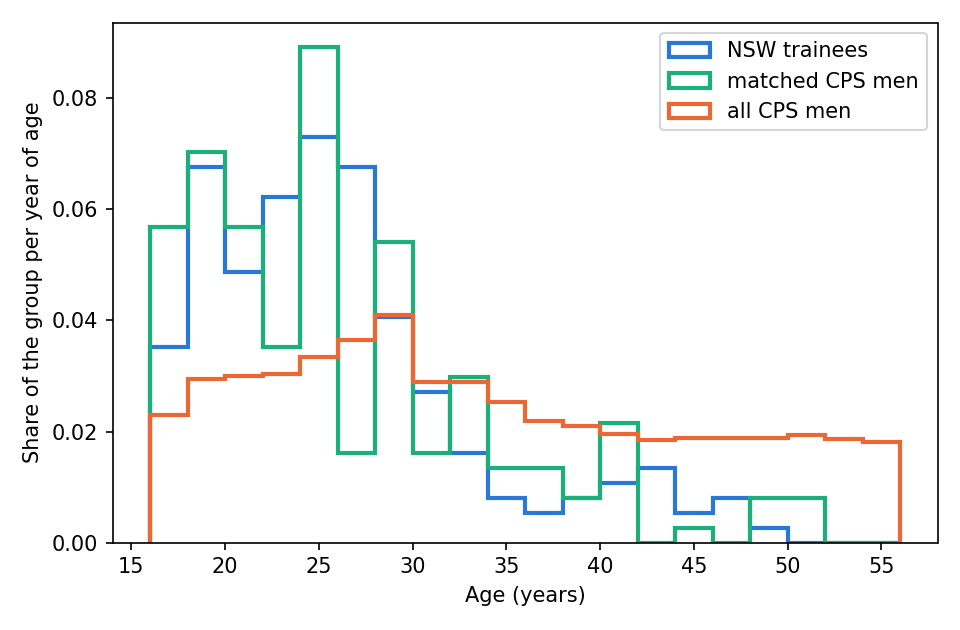

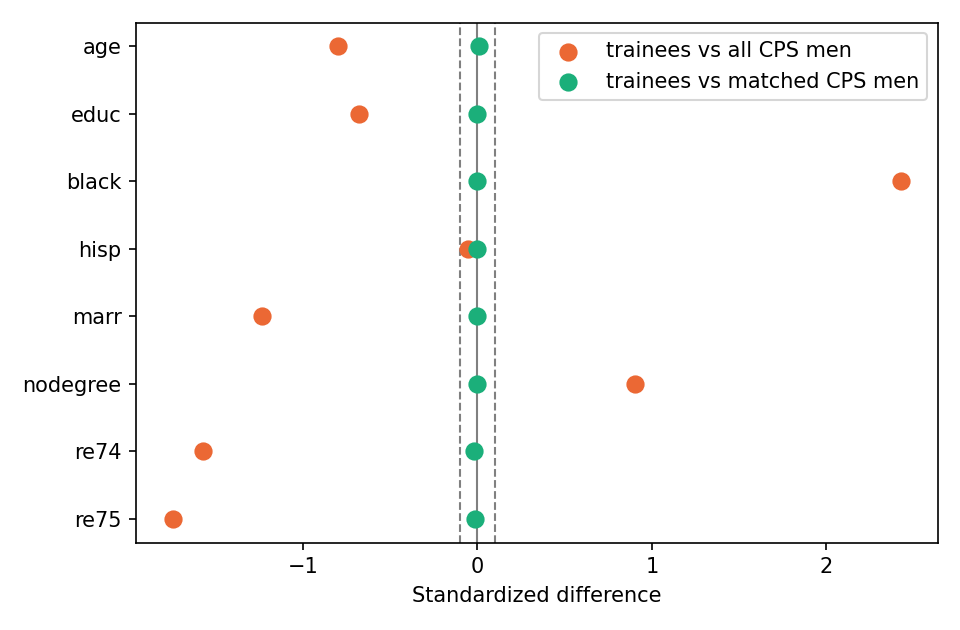

**Your turn.** Compute the covariate means of the CPS men matched by the **normalized Euclidean** distance, `matches["Normalized Euclidean"]`, and compare them with the table above.

In [ ]:
# TODO: replace None
matched_norm = None   # one mean per covariate, in the order of X_vars
if matched_norm is not None:
    print(pd.Series(matched_norm, index=X_vars).round(2))

In [ ]:
# Check (do not edit)
if matched_norm is None:
    print("not done yet")
else:
    ok = np.allclose(matched_norm, X0[matches["Normalized Euclidean"]].mean(axis=0))
    print("matches" if ok else "does not match: which rows of X0 did you average?")

**Question 5.** Matching makes the groups much more alike, but not identical: the remaining differences $X_i - X_{j(i)}$ are the **matching discrepancies**. Which covariates still differ? How could the remaining differences bias the estimate? (Bias-corrected matching removes part of this bias with a regression; we do not cover it here. See the references.)

*Your answer to Question 5:*

## Summary

In [ ]:
summary = pd.Series({
    "Experimental benchmark": benchmark,
    "Naive NSW - CPS": naive,
    "Subclassification, " + " + ".join(steps[2]): subclass_att(steps[2])["ATT"],
    "Nearest neighbor, normalized Euclidean": (y1 - y0[matches["Normalized Euclidean"]]).mean(),
    "Nearest neighbor, Mahalanobis": (y1 - y0[matches["Mahalanobis"]]).mean(),
}).round(1)
summary